### **Neural Network**

In [248]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import confusion_matrix, classification_report

| ტერმინი       | მნიშვნელობა                                                           |
| ------------- | --------------------------------------------------------------------- |
| Input         | ის, რასაც ვაძლევთ მოდელს                                              |
| Output        | შედეგი, რომელსაც მოდელი აბრუნებს                                      |
| Weight        | წონა, რომელიც ახდენს გავლენას შედეგზე                                 |
| Bias          | დამატებითი რიცხვი შედეგის რეგულირებისთვის                             |
| Activation    | ფუნქცია, რომელიც წყვეტს, რა დაბრუნდეს                                 |
| Loss          | შეცდომა — რამდენად შორსაა მოდელის პროგნოზი ნამდვილი მნიშვნელობისგან   |
| Optimizer| ალგორითმი, რომელიც ცვლის weight-ებს და bias-ს ისე, რომ Loss შემცირდეს |
| Epoch         | რამდენჯერ გადაუვლის მოდელი მთელ მონაცემებს (რამდენჯერ გაიმეორებს)     |

<img src="../../images/nn.webp" width="1000">

### Model Layers

| Layer                        | Description                                                                                                                                                 | When to Use                                                                                                                                            | Why                                                                                                                                                                                     | What It Does                                                                                                                                                                                                                                                                                                                                                                                           | Torch Equivalent                                                                                                                                                                                             |
| ---------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------ | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| Dense (Fully Connected)  | შრე, სადაც თითოეული შემავალი ნეირონი დაკავშირებულია თითოეულ გამომავალ ნეირონთან.                         | • მარტივ Multilayer Perceptron-ში ცხრილის სახით წარმოდგენილ ან flattened მონაცემებისთვის.  | • იჭერს გლობალურ დამოკიდებულებებს შესულ მახასიათებლებს შორის.  <br>• გარდაქმნის მაღალ განზომილებებიან მახასიათებლებს გარდაქმნის.                       | გამოითვლის $y = xW^T + b$, სადაც $x$ არის input, $W$ არის წონების მატრიცა, $b$ არის bias.                                                                                                                                                                              | `nn.Linear(in_features, out_features)`                                                                                                                                                                       |
| Dropout                  | რეგულარიზაციის ფენა, რომელიც შემთხვევითად გამოთიშავს შემავალი ნეირონების ნაწილს  სწავლების პროცესში.                                                             | • Dense ან Conv ბლოკების შემდეგ, როდესაც overfitting ხდება (validation loss ≫ training loss). | •  თავიდან აცილებს ნეირონების კო–ადაპტაციას, redundant representations-ის იძულებით სწავლების მექანიზმით. <br>•  მოქმედებს როგორც მარტივი regularization-ის ფორმა.                                          | სწავლების პროცესში თითოეული შემავალი ტენზორის ელემენტი ნულდება ალბათობით 𝑝. | `nn.Dropout(p)`                                                                                                                                                                                              |
| Pooling (Max/Avg)        | A downsampling layer, რომელიც ამცირებს განზომილებას ლოკალური (patch) პაჩის აგრეგირებით - მაქსიმუმის (MaxPooling) ან საშუალოს (AvgPooling) სახით.                                      | • Conv ფენის შემდეგ, სივრცული განზომილებების შემცირებისთვის. | • ამცირებს გამოთვლით ხარჯს და შეამცირებს პარამეტრების რაოდენობას სივრცული განზომილების შემცირებით. <br>• აჯამებს ლოკალურ რეგიონებს, რაც აუმჯობესებს ქსელის მდგრადობას მცირე ცვლილებების მიმართ.                                   | MaxPooling2D: Input მახასიათებლებს ყოფს პაჩებად (patches) ზომით $(K_h,\,K_w)$ და აბრუნებს მაქსიმალურ მნიშვნელობას თითოეული პაჩიდან.  <br>AvgPooling2D: ანალოგიურად, იღებს საშუალოს თითოეული პაჩიდან. Output tensor shape ხდება $(B,\,C,\,H_{\text{out}},\,W_{\text{out}})$.                                                          | `nn.MaxPool2d(kernel_size, stride, padding)`  <br> `nn.AvgPool2d(kernel_size, stride, padding)`                                                                                                              |
| Batch Normalization      | შრე, რომელიც input-ის ნორმალიზაციას აკეთებს ბაჩის გასწვრივ| • Linear ან Conv შრის შემდეგ (ხშირად activation შრემდე)  რომ დაარეგულიროს და დააჩქაროს სწავლება.                                                       | • ზოგჯერ ხდის Dropout–ს არასაჭიროს.                          | For each channel (feature dimension) over a mini-batch, computes mean $\mu$ and variance $\sigma^2$.  Normalizes: $\hat{x} = (x - \mu)/\sqrt{\sigma^2 + \epsilon}$.  Then outputs $y = \gamma \hat{x} + \beta$, where $\gamma,\beta$ are learned per-channel.                                                                                                                                          | `nn.BatchNorm1d(num_features)`  <br> `nn.BatchNorm2d(num_features)`                                                                                                                                          |
| Convolutional (Conv)     | შრე, რომელიც ფილტრაციების სიმრავლეს ადებს input-ს იმისათვის რომ ამოიცნოს ლოკალური pattern-ები.                                        | • კომპიუტერული ხედვის (CV) ამოცანებში (image classification, segmentation, detection).| •  იყენებს ადგილობრივ კორლაციებს და წონის გაზიარებას (weight sharing) პარამეტრების რაოდენობის შესამცირებლად. | Conv2d: input ფორმით $(B,\,C_{\text{in}},\,H,\,W)$ და ფილტრი ფორმით $(C_{\text{out}},\,C_{\text{in}},\,K_h,\,K_w)$, აცოცებს თითოეულ ფილტრს input-ზე. Output shape: $(B,\,C_{\text{out}},\,H_{\text{out}},\,W_{\text{out}})$.       | `nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0)`  <br> `nn.Conv1d(in_channels, out_channels, kernel_size, stride=1, padding=0)`                                                      |
| Recurrent (RNN/LSTM/GRU) | შრე, რომელიც წარმოადგენს მიმდევრობით მონაცემებს დროის გარკვეულ მომენტში, hidden state-ის მეშვებით დროებითი დამოკიდებულებების ასახვა.                          | • Sequential data tasks: language modeling, speech recognition, time-series forecasting.  <br>• როდესაც დამოკიდებულებების აღმოჩენა ძალიან მნიშვნეოვანია   | • ასახავს დროობრივ (sequential) ურთიერთობებს context-ის hidden state-ებში გატარებით.  <br>• LSTM/GRU variants mitigate vanishing/exploding gradients.                              | RNN (vanilla): $h_t = \phi(W_h h_{t-1} + W_x x_t + b)$ თითოელი timestep $t$-თვის.  <br>LSTM: იყენებს gated სტრუქტურას (input, forget, output gates).  <br>GRU: გამარტივებული gated RNN update და reset gate-ებით.  Input shape (batch_first=True): $(B,\,L,\,\text{input\_size})$.  Output shape: $(B,\,L,\,\text{hidden\_size})$. | `nn.RNN(input_size, hidden_size, num_layers, batch_first=True)`  <br> `nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)`  <br> `nn.GRU(input_size, hidden_size, num_layers, batch_first=True)` |
| Flatten                  | ფენა, რომელიც უცვლის მრავალგანზომილებიან ტენზორს ფორმას (მაგ., $(B,\,C,\,H,\,W)$) ფორმის გარდაქმნა 2D tensor-ად: $(B,\,C\times H\times W)$.                              | • convolutional ფენის შემდეგ, convolutional output-ს სანამ მივაწვდით Dense (Linear) ფენას.                                                                    | • convolutional ანდა multi-dimensional tensor-ების დამაკავშირებელი fully connected classifiers or regressors.                                                                                      | თუ input აქვს ფორმა $(B,\,D_1,\,D_2,\dots,\,D_n)$, Flatten წარმოქმნის ფორმას $(B,\,D_1 \times D_2 \times \dots \times D_n)$.  სასწავლი პარამეტრები არ აქვს.                                                                                                                                                                                                                                                    | `nn.Flatten()`                                                                                                                                                                                               |
| Activation               |  არაფრფივი ფუნქცია, რომელიც მოედება თითოეულ input-ს (მაგ., ReLU, Sigmoid, Tanh, Softmax).                                                           | • Conv ან Dense ფენების შემდეგ, რათა დანერგოს არაწრფივობა და ქსელს შეეძლოს რთული ფუნციების სწავლა.                                     | • არასიწრფივის გარეშე, ბევრი შრე ჩამოინგრეოდა ერთი წრფივი ტრანსფორმაციით.  <br>• თითოეული აქტივაციის ფუნცია უკეთ შეეფერება გარკვეულ tasks (მაგ., Softmax for multi-class probabilities). | ფუნქციები:<br>• ReLU: $f(x)=\max(0,x)$  <br>• Sigmoid: $f(x)=1/(1+e^{-x})$  <br>• Tanh: $f(x)=\tfrac{e^x - e^{-x}}{e^x + e^{-x}}$  <br>• Softmax: $f(x_i) = e^{x_i} / \sum_j e^{x_j}$           | `nn.ReLU()`  <br> `nn.Sigmoid()`  <br> `nn.Tanh()`  <br> `nn.Softmax(dim=…)`                                                                                                                                 |

In [253]:
# input
input_x = torch.randn(3, 6, 2)
input_x.shape

torch.Size([3, 6, 2])

In [255]:
# Flatten
flatten = nn.Flatten() # start_dim (default = 1), end_dim (default = -1). 
flat_x = flatten(input_x)            
flat_x.shape

torch.Size([3, 12])

In [256]:
# Linear layer
layer1 = nn.Linear(in_features=12, out_features=6)
hidden1 = layer1(flat_x)
hidden1.shape

torch.Size([3, 6])

In [177]:
# Activation ReLU
print(f"Before ReLU: {hidden1}\n")
hidden1 = nn.ReLU()(hidden1)
print(f"After ReLU: {hidden1}")

Before ReLU: tensor([[-0.1598, -0.1493, -1.2889, -0.6877, -0.6168,  0.6843],
        [-0.3187,  0.6895,  0.2231, -0.8523, -0.7595, -0.1797],
        [ 0.1924, -0.7841, -0.0284,  0.3080,  0.0955, -0.2228]],
       grad_fn=<AddmmBackward0>)

After ReLU: tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.6843],
        [0.0000, 0.6895, 0.2231, 0.0000, 0.0000, 0.0000],
        [0.1924, 0.0000, 0.0000, 0.3080, 0.0955, 0.0000]],
       grad_fn=<ReluBackward0>)


In [260]:
# Sequential
seq_modules = nn.Sequential(
    nn.Flatten(),
    nn.Linear(in_features=12, out_features=6),
    nn.ReLU(),
    nn.Linear(6, 2),
    nn.Softmax(dim=1)
)

pred_probab = seq_modules(input_x)
pred_probab

tensor([[0.5181, 0.4819],
        [0.4267, 0.5733],
        [0.3797, 0.6203]], grad_fn=<SoftmaxBackward0>)

In [261]:
pred_probab.argmax(dim=1)

tensor([0, 1, 1])

| Problem type                  | Loss function               | Optimizer                            |
| ----------------------------- | --------------------------- | ------------------------------------ |
| Regression                | MSELoss, MAELoss | SGD (+Momentum), Adam, AdamW (weight_decay (or L2 regularization))|
| Binary classification     | BCEWithLogitsLoss       | Adam, AdamW, SGD                 |
| Multiclass classification | CrossEntropyLoss        | Adam, AdamW, SGD                 |

CrossEntropyLoss აერთიანებს: Softmax + Log + Negative Log-Likelihood

* Cross-Entropy ითხოვს, რომ სწორი კლასის ალბათობა მაქსიმალურად ახლოს იყოს 1-თან.
    - თუ სწორი კლასის ალბათობაა 0.60 → მოდელი მაინც ისჯება
    - თუ ალბათობაა 0.95 → დანაკარგი მნიშვნელოვნად მცირდება

* მკაცრად სჯის თავდაჯერებულ შეცდომებს
    - თუ მოდელი ძალიან თავდაჯერებულია (მაგ. 0.99), მაგრამ არასწორ კლასს ირჩევს
    - მაშინ დანაკარგი ძალიან დიდია: $-\log(0.01) \approx 4.6$
    - დიდი დანაკარგი ⇒ დიდი გრადიენტი ⇒ ძლიერი კორექცია
* უზრუნველყოფს გლუვ და სტაბილურ გრადიენტებს. Softmax-ისა და ლოგარითმის კომბინაციის გამო თავიდან გვარიდებს:
     - უეცარ ნახტომებს
    - არასტაბილურ სწავლებას
    - გრადიენტის გაქრობას

* შედეგი: სტაბილური და ეფექტური სწავლება, განსაკუთრებით საწყის ეტაპზე.

#### Classifination with NN

In [275]:
# სინთეტიკური მონაცემები
points = {
    "A": (1.72, 70, 1),
    "B": (1.68, 68, 1),
    "C": (1.74, 66, 1),
    "D": (1.60, 55, 2),
    "E": (1.63, 56, 2),
    "F": (1.62, 54, 2),
}
df_points = pd.DataFrame(points, index=["x", "y", "z"]).T
df_points["class"] = [0, 0, 0, 1, 1, 1]
df_points

,x,y,z,class
A,1.72,70.0,1.0,0
B,1.68,68.0,1.0,0
C,1.74,66.0,1.0,0
D,1.60,55.0,2.0,1
E,1.63,56.0,2.0,1
F,1.62,54.0,2.0,1


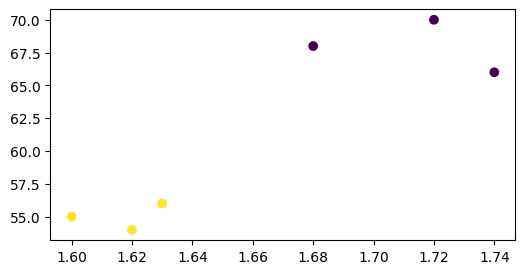

In [276]:
plt.figure(figsize=(6, 3))
plt.scatter(df_points["x"], df_points["y"], c=df_points["class"]);

In [277]:
X = df_points.drop(columns="class").values
y = df_points["class"].values

In [278]:
input_x, y_true = torch.from_numpy(X).float(), torch.from_numpy(y).long()
input_x.shape, y_true.shape

(torch.Size([6, 3]), torch.Size([6]))

In [279]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3,  3),   
            nn.ReLU(),
            nn.Linear(3,  2)
        )
    def forward(self, x):
        return self.net(x)

In [280]:
model = SimpleNet()
model

SimpleNet(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=3, bias=True)
    (1): ReLU()
    (2): Linear(in_features=3, out_features=2, bias=True)
  )
)

In [281]:
loss_fn   = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-2) # Adaptive Moment Estimation

In [284]:
# Training
model.train()
for epoch in range(100):
    y_pred = model(input_x)           # shape: [batch, num_classes]
    loss  = loss_fn(y_pred, y_true)   # CrossEntropyLoss does Log-Softmax + NLL (Negative Log‐Likelihood Loss)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [288]:
# Evaluation
new_x = torch.tensor([
    [1.61, 58, 2],
    [1.70, 70, 1]
], dtype=torch.float32)

# Modell in Eval-Modus
model.eval()
with torch.no_grad():
    logits = model(new_x)                    # raw scores
    probs  = torch.softmax(logits, dim=1)    # now in [0,1], sum to 1
    preds = probs.argmax(dim=1)              # 0 or 1
preds

tensor([1, 0])

#### Regression with NN

In [189]:
# სინთეტიკური მონაცემები
df_reg = pd.DataFrame({
    "feature1": [1, 2, 3, 4, 5, 6],
    "feature2": [2, 4, 6, 8, 10, 12],
    "target":   [2.5, 5.1, 7.4, 9.8, 12.0, 14.2]
})

X = df_reg[["feature1", "feature2"]].values  
y = df_reg["target"].values                  

In [190]:
# In Tensors
input_x = torch.tensor(X, dtype=torch.float32)  
y_true  = torch.tensor(y, dtype=torch.float32).unsqueeze(1)  

In [191]:
# Modell (simple MLP with Linear → ReLU → Linear)
class SimpleRegNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2,  4),   
            nn.ReLU(),
            nn.Linear(4,  1)    
        )
    def forward(self, x):
        return self.net(x)

In [192]:
model = SimpleRegNet()

In [193]:
loss_fn = nn.MSELoss()     # Mean Squared Error
optimizer = optim.Adam(model.parameters(), lr=1e-2)

In [194]:
# Training
model.train()
for epoch in range(1, 101):
    # Forward
    preds = model(input_x)             
    loss  = loss_fn(preds, y_true) 

    # Backward & Update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        print(f"Epoch {epoch:02d} — Loss: {loss.item():.3f}")

Epoch 20 — Loss: 20.774
Epoch 40 — Loss: 0.992
Epoch 60 — Loss: 0.061
Epoch 80 — Loss: 0.066
Epoch 100 — Loss: 0.055


In [195]:
model.eval()
with torch.no_grad():
    predictions = model(input_x).squeeze(1) 
    for i, (true, pred) in enumerate(zip(y, predictions)):
        print(f"Sample {i}: True={true:.2f}, Pred={pred:.2f}")

Sample 0: True=2.50, Pred=3.03
Sample 1: True=5.10, Pred=5.27
Sample 2: True=7.40, Pred=7.50
Sample 3: True=9.80, Pred=9.73
Sample 4: True=12.00, Pred=11.97
Sample 5: True=14.20, Pred=14.20


| Task                        | Hidden Blocks (repeat as needed)     | Output Layer                                  | Activation on Output      | Typical Loss       |
| --------------------------- | ------------------------------------ | --------------------------------------------- | ------------------------- | ------------------ |
| Classification (K>2)    | Dense → BatchNorm → ReLU → (Dropout) | Dense(K) → Softmax                            | Softmax (K-way prob.)     | Categorical CE     |
| Classification (Binary) | Dense → BatchNorm → ReLU → (Dropout) | Dense(1)  → Sigmoid    OR  Dense(2) → Softmax | Sigmoid / Softmax (2-way) | Binary CE / Cat CE |
| Regression (M=1)        | Dense → BatchNorm → ReLU → (Dropout) | Dense(1)  (no activation = linear)            | Linear (i.e., identity)   | MSE, MAE, Huber    |
| Regression (M>1)        | Dense → BatchNorm → ReLU → (Dropout) | Dense(M) (linear)                             | Linear                    | MSE, MAE, Huber    |

### Simple NN with Iris data 

In [196]:
iris = load_iris()
X = iris.data            # shape: (150, 4)
y = iris.target          # shape: (150,) with labels 0,1,2

pd.DataFrame(X, columns=iris.feature_names).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [197]:
# stratify=y ნიშნავს, რომ train და test ნაწილებში კლასების განაწილება იგივე დარჩება, რაც მთლიან მონაცემებშია.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [198]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [199]:
X_train = torch.tensor(X_train, dtype=torch.float32)  # shape: (120, 4)
y_train = torch.tensor(y_train, dtype=torch.long)     # shape: (120,)
X_test  = torch.tensor(X_test,  dtype=torch.float32)  # shape: (30, 4)
y_test  = torch.tensor(y_test,  dtype=torch.long)     # shape: (30,)

In [200]:
# Define a small feedforward network
# Input dim = 4, Hidden = 10, Output = 3 classes
class IrisNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 10),
            nn.ReLU(),
            nn.Linear(10, 3)    # raw logits for 3 classes
        )

    def forward(self, x):
        return self.net(x)

model = IrisNet()

In [201]:
# Loss and optimizer
criterion = nn.CrossEntropyLoss()     
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)

In [202]:
# Training loop
n_epochs = 150
for epoch in range(1, n_epochs + 1):
    model.train()
    optimizer.zero_grad()

    logits = model(X_train)             # shape: (120, 3)
    loss   = criterion(logits, y_train)

    loss.backward()
    optimizer.step()

    if epoch % 20 == 0 or epoch == 1:
        # Compute training accuracy
        with torch.no_grad():
            preds = torch.softmax(logits, dim=1)  # shape: (120,)
            preds = preds.argmax(dim=1)          
            correct = (preds == y_train).sum().item()
            acc = correct / y_train.size(0)
        print(f"Epoch {epoch:3d}/{n_epochs}  —  Loss: {loss.item():.4f},  Train Acc: {acc * 100:.2f}%")

Epoch   1/150  —  Loss: 1.2620,  Train Acc: 33.33%
Epoch  20/150  —  Loss: 0.3683,  Train Acc: 85.83%
Epoch  40/150  —  Loss: 0.1979,  Train Acc: 90.83%
Epoch  60/150  —  Loss: 0.1097,  Train Acc: 97.50%
Epoch  80/150  —  Loss: 0.0726,  Train Acc: 97.50%
Epoch 100/150  —  Loss: 0.0623,  Train Acc: 97.50%
Epoch 120/150  —  Loss: 0.0569,  Train Acc: 97.50%
Epoch 140/150  —  Loss: 0.0535,  Train Acc: 97.50%


In [203]:
# Evaluate on test set
model.eval()
with torch.no_grad():
    test_logits = model(X_test)                # shape: (30, 3)
    y_pred  = torch.softmax(test_logits, dim=1)
    y_pred  = y_pred.argmax(dim=1)    # shape: (30,)
    correct     = (y_pred == y_test).sum().item()
    test_acc    = correct / y_test.size(0)

print(f"\nTest accuracy: {test_acc * 100:.2f}%")


Test accuracy: 96.67%


In [204]:
# ევალუაციის მეტრიკები
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



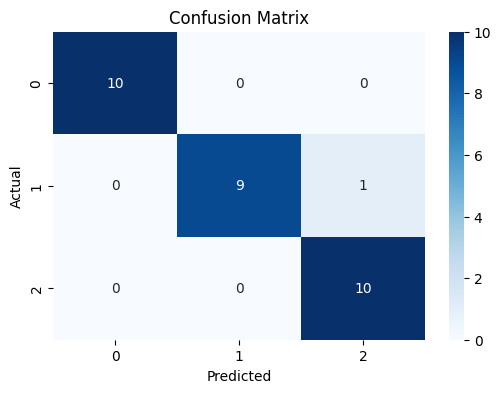

In [205]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Multilayer Perceptron (MLP)
MLP-ს (type of feedforward neural network) აქვს სამი ან მეტი შრე, input layer, ერთი ან მეტი hidden layers და ერთი output layer. იყენებს არაწრფივ activation ფუნქციებს.
MLPRegressor
   * `hidden_layer_sizes=(50,)` ნიშნავს ერთი დამალულ ფენას 50 ნეირონით.
   * `activation="relu"` გამოყენებულია ReLU (Rectified Linear Unit).
   * `solver="adam"` არის პოპულარული ოპტიმიზატორი (Adaptive Moment Estimation).
   * `learning_rate_init=0.001` არის საწყისი სასწავლო სიჩქარე (learning rate).
   * `max_iter=300` განსაზღვრავს მაქსიმალურ ეპოქის რაოდენობას.

In [210]:
# California Housing მონაცემების ჩატვირთვა
data = fetch_california_housing()
X = data.data       # მახასიათებლები: shape (20640, 8)
y = data.target     # Median house value (/100000)

pd.DataFrame(X, columns=data.feature_names).head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [211]:
# Train/Test გაყოფა (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [212]:
# StandardScaler (mean=0, std=1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [235]:
# მარტივი ნეირონული ქსელი MLPRegressor–ის საშუალებით
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=3e-4,
    batch_size=256,
    max_iter=2000,
    early_stopping=True,
    n_iter_no_change=20,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)

,loss,'squared_error'
,hidden_layer_sizes,"(64, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,256
,learning_rate,'constant'
,learning_rate_init,0.0003
,power_t,0.5
,max_iter,2000
,shuffle,True


In [236]:
# პროგნოზი სატესტო სიმრავლეზე
y_pred = mlp.predict(X_test_scaled)

In [237]:
# მოდელის ევალუაცია
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 0.35
Mean Squared Error (MSE): 0.28
Root Mean Squared Error (RMSE): 0.53
R² Score: 0.79


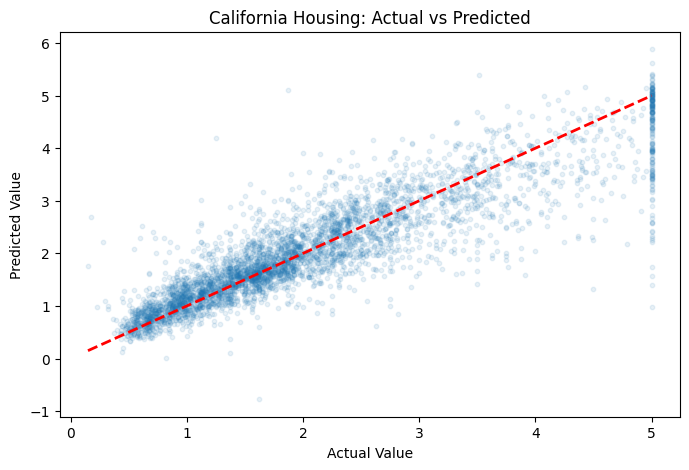

In [238]:
# Scatter: Actual vs Predicted
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, s=10, alpha=0.1)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--", lw=2
)
plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.title(f"California Housing: Actual vs Predicted")
plt.show()

### MNIST

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html) 

In [239]:
# Hyperparameters
batch_size = 64
learning_rate = 0.01
momentum = 0.9
n_epochs = 5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [240]:
# Dataset + DataLoaders
#    - MNIST images are 28×28 grayscale (0–255). We convert to [0.0–1.0] and flatten later.
transform = transforms.Compose([
    transforms.ToTensor(),                    # converts to tensor with shape (1,28,28), values in [0,1]
    transforms.Normalize((0.1307,), (0.3081,)) # normalize with MNIST mean/std (optional but common)
])

train_dataset = datasets.MNIST(
    root="../../datasets/", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="../../datasets/", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

In [241]:
# Define a simple feedforward neural network
#    - Input: 784 (28×28 flattened)
#    - Hidden: 128 units + ReLU
#    - Output: 10 logits (one per digit class)
class FeedforwardMNIST(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),             # (N,1,28,28) → (N,784)
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)        # raw logits for 10 classes
        )

    def forward(self, x):
        return self.net(x)

model = FeedforwardMNIST().to(device)

In [242]:
# Loss function and optimizer
criterion = nn.CrossEntropyLoss()                   # expects raw logits + integer labels [0..9]
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)

In [243]:
# Training loop
for epoch in range(1, n_epochs + 1):
    model.train()
    running_loss = 0.0
    for batch_idx, (images, labels) in enumerate(train_loader, start=1):
        images = images.to(device)   # shape: (batch_size, 1, 28, 28)
        labels = labels.to(device)   # shape: (batch_size,)

        optimizer.zero_grad()
        logits = model(images)       # shape: (batch_size, 10)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if batch_idx % 200 == 0:
            avg_loss = running_loss / 200
            print(f"Epoch [{epoch}/{n_epochs}]  Batch [{batch_idx}/{len(train_loader)}]  —  Loss: {avg_loss:.4f}")
            running_loss = 0.0

Epoch [1/5]  Batch [200/938]  —  Loss: 0.5381
Epoch [1/5]  Batch [400/938]  —  Loss: 0.2572
Epoch [1/5]  Batch [600/938]  —  Loss: 0.2095
Epoch [1/5]  Batch [800/938]  —  Loss: 0.1823
Epoch [2/5]  Batch [200/938]  —  Loss: 0.1314
Epoch [2/5]  Batch [400/938]  —  Loss: 0.1223
Epoch [2/5]  Batch [600/938]  —  Loss: 0.1085
Epoch [2/5]  Batch [800/938]  —  Loss: 0.1116
Epoch [3/5]  Batch [200/938]  —  Loss: 0.0814
Epoch [3/5]  Batch [400/938]  —  Loss: 0.0780
Epoch [3/5]  Batch [600/938]  —  Loss: 0.0776
Epoch [3/5]  Batch [800/938]  —  Loss: 0.0792
Epoch [4/5]  Batch [200/938]  —  Loss: 0.0578
Epoch [4/5]  Batch [400/938]  —  Loss: 0.0574
Epoch [4/5]  Batch [600/938]  —  Loss: 0.0607
Epoch [4/5]  Batch [800/938]  —  Loss: 0.0665
Epoch [5/5]  Batch [200/938]  —  Loss: 0.0499
Epoch [5/5]  Batch [400/938]  —  Loss: 0.0490
Epoch [5/5]  Batch [600/938]  —  Loss: 0.0504
Epoch [5/5]  Batch [800/938]  —  Loss: 0.0458


In [244]:
# Evaluate on train and test sets
def evaluate(loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return correct / total

train_acc = evaluate(train_loader)
test_acc  = evaluate(test_loader)
print(f"\nFinal Train Accuracy: {train_acc * 100:.2f}%")
print(f"Final Test  Accuracy: {test_acc  * 100:.2f}%")


Final Train Accuracy: 99.09%
Final Test  Accuracy: 97.88%


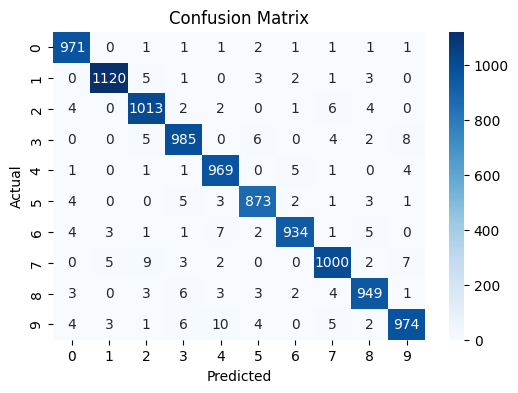

In [245]:
# Confusion Matrix Visualization
#    First collect all true labels and predictions on the test set:
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

| ჰიპერპარამეტრი             | ტიპიური მნიშვნელობები / არჩევანი                                                                                                  |
| -------------------------- | --------------------------------------------------------------------------------------------------------------------------------- |
| Learning Rate      | 0.001, 0.0001, 0.01; შესაძლებელია დიაპაზონი 0.00001 – 0.1                                                        |
| Batch Size | 2-ის ხარისხები: 16, 32, 64, 128, 256                                                          |
| Epochs      | 10–100; პატარა მონაცემებისთვის 5–20; ძალიან დიდი მონაცემების – 50–200                                                   |
| Optimizer           | Adam (LR \~0.001), SGD + momentum (LR \~0.01 – 0.001, momentum=0.9), RMSprop (LR \~0.001), AdamW (LR \~0.001)                         |
| Loss Function       | • Classification (multi-class): Categorical Cross-Entropy <br>• Classification (binary): Binary Cross-Entropy <br>• Regression (single/multiple): MSE (L2), MAE (L1), Huber |

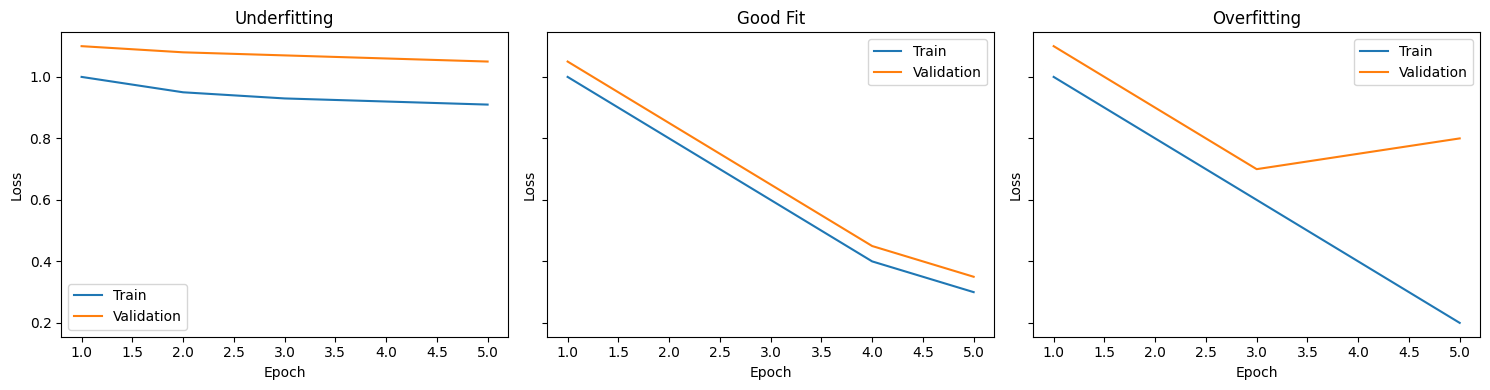

In [56]:
epochs = range(1, 6)

train_under = [1.0, 0.95, 0.93, 0.92, 0.91]
val_under   = [1.1, 1.08, 1.07, 1.06, 1.05]

train_good = [1.0, 0.8, 0.6, 0.4, 0.3]
val_good   = [1.05, 0.85, 0.65, 0.45, 0.35]

train_over = [1.0, 0.8, 0.6, 0.4, 0.2]
val_over   = [1.1, 0.9, 0.7, 0.75, 0.8]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# Underfitting
axes[0].plot(epochs, train_under)
axes[0].plot(epochs, val_under)
axes[0].set_title("Underfitting")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(["Train", "Validation"])

# Good Fit
axes[1].plot(epochs, train_good)
axes[1].plot(epochs, val_good)
axes[1].set_title("Good Fit")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(["Train", "Validation"])

# Overfitting
axes[2].plot(epochs, train_over)
axes[2].plot(epochs, val_over)
axes[2].set_title("Overfitting")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend(["Train", "Validation"])

plt.tight_layout()
plt.show()

| მოქმედება                    | Overfitting-ის წინააღმდეგ             | Underfitting-ის წინააღმდეგ          |
| -------------------------------- | ----------------------------------------- | --------------------------------------- |
| Model complexity             | უფრო პატარა არქიტექტურა / ნაკლები ნეირონი      | უფრო დიდი არქიტექტურა / მეტი ნეირონი         |
| Regularization                | L2 (წონების დასუსტება), Dropout-ის გაზრდა | რეგულარიზაციის შემცირება                |
| Dataset size           | მეტი სატრენინგო მონაცემი                    | –                                       |
| Data augmentation         | Data augmentation-ის გამოყენება          | –                                       |
| Training epochs | ადრე შეჩერება (Early Stopping)            | ეპოქების რაოდენობის გაზრდა              |
| Feature engineering    | –                                         | მნიშვნელოვან მახასიათებლებზე ფოკუსირება |

### Recurrent Neural Network (RNN)
RNN არის ხელოვნური ნეირონული ქსელის ტიპი, რომელიც სპეციალურად შექმნილია დროით დამოკიდებული მონაცემების დასამუშავებლად — ანუ ისეთ მონაცემებთან მუშაობისთვის, სადაც რიგითობა/მიმდევრობა მნიშვნელოვანია. 

Feed-forward ნეირონული ქსელებისთვის შეგვიძლია input-სა და output-ს შორის დამოკიდებულება გამოვხატოთ შემდეგი სახით: შეყვანილი $x_i$ გადის ქსელში, მუშავდება კავშირებისა და წონების საშუალებით და იძლევა გამომავალ $y_i$–ს. ასეთ ქსელს შეიძლება მივანიჭოთ მარტივი ფუნქციის ფორმა:

$$
f(x_i) \;\to\; y_i
$$

მეორეს მხრივ, Recurrent Neural Network (RNN) აღწერილია ოდნავ განსხვავებული ფუნქციით:

$$
f(x_t, h_t) \;\to\; (y_t,\,h_{t+1})
$$

ინდექსები $t$ და $t+1$ მიუთითებენ, რომ input-სა და output-ს შორის არსებობს თანმიმდევრობა. 

RNN-ის უნიკალურობა ისაა, რომ ის იმახსოვრებს წარსულ ინფორმაციას, რაც ეხმარება მომდევნო გადაწყვეტილებების მიღებაში.

როდესაც RNN გამოყენებულია დროით დამოკიდებული მონაცემების დასამუშავებლად, რაც უფრო მეტი input-ის დამუშავება ხდება, უჭირს წინა ნაბიჯებიდან ინფორმაციის შენარჩუნების (short memory). Long Short-Term Memory (LSTM) არის recurrent neural network-ის არქიტექტურა. LSTM-ქსელები მოითავსებენ LSTM-ბლოკებს, რომელთაც გააჩნიათ ერთი უჯრედი (cell) და სამი gates - an input gate, an output gate and a forget gate. უჯრედი ინახავს მნიშვნელობებს, ხოლო gates არეგულირებენ უჯრედის ოპერაციების წაკითხვას, ჩაწერას და წაშლას. 
Training-ის დროს LSTM-ქსელი სწავლობს, როგორ მართოს მეხსიერება, რათა შეინარჩუნოს ამოცანისთვის საჭირო ინფორმაცია.

### Stock data

In [289]:
# მონაცემების ჩატვირთვა
df_stock = pd.read_excel("../../datasets/vonovia/Historical_Data_Vonovia.xlsx")
df_stock["Date"] = pd.to_datetime(df_stock["Date"], format="%d.%m.%Y")
df_stock["Year"] = df_stock["Date"].dt.year
df_stock.head() 

,Date,Open,High,Low,Close,Volume,Year
0,2013-07-11,15.193,15.638,15.167,15.593,3.679225e+06,2013
1,2013-07-12,15.567,15.966,15.549,15.638,5.104107e+05,2013
2,2013-07-15,15.726,16.029,15.593,16.029,3.611333e+05,2013
3,2013-07-16,16.144,16.437,15.966,15.993,2.729588e+05,2013
4,2013-07-17,16.215,16.215,15.904,16.126,1.154373e+06,2013


In [290]:
# Close price forecast for 2024
hist_data = df_stock[df_stock["Year"] < 2024].set_index("Date")["Close"] # აქციების ფასი 2024 წლამდე
actual_2024 = df_stock[(df_stock["Year"] == 2024)].set_index("Date")["Close"] # აქციების ფასი 2024 წელს

##### Long short-term memory (LSTM) 

<img src="../../images/rnn.png" width="600">
<img src="../../images/lstm.png" width="600">

In [291]:
def create_dataset(data, time_step=1):
    X, Y = [], []
    for i in range(len(data) - time_step):
        seq = data[i:(i + time_step), 0]
        X.append(seq)
        Y.append(data[i + time_step, 0])
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(Y, dtype=torch.float32).unsqueeze(1)
    )

In [292]:
# Hyperparameter
time_step = 60
batch_size = 1
epochs = 2
lr = 1e-3

In [293]:
# Scaling
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_hist = scaler.fit_transform(hist_data.values.reshape(-1, 1))
concat_2024 = pd.concat([hist_data[-time_step:], actual_2024])
scaled_2024 = scaler.transform(concat_2024.values.reshape(-1, 1))

# Training- und Testdata
X_train, y_train = create_dataset(scaled_hist, time_step)
X_test,  y_test  = create_dataset(scaled_2024, time_step)

# Reshape for LSTM: [samples, seq_len, features]
X_train = X_train.unsqueeze(2)  # Shape: [N_train, time_step, 1]
X_test  = X_test.unsqueeze(2)   # Shape: [N_test,  time_step, 1]

# DataLoader
train_ds = torch.utils.data.TensorDataset(X_train, y_train)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True)

/var/folders/53/nhc_49ds71j4rt8wg28czyhr0000gn/T/ipykernel_85475/2677165948.py:8: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:256.)
  torch.tensor(X, dtype=torch.float32),


In [294]:
# Modell
class LSTMForecast(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        self.fc1  = nn.Linear(hidden_size, 25)
        self.fc2  = nn.Linear(25, 1)

    def forward(self, x):
        # x: [batch, seq_len, features]
        out, _ = self.lstm(x)            # out: [batch, seq_len, hidden_size]
        out = out[:, -1, :]              # last time step only → [batch, hidden_size]
        out = nn.functional.relu(self.fc1(out))
        return self.fc2(out)  

In [295]:
model = LSTMForecast()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

In [296]:
# Training
model.train()
for epoch in range(1, epochs + 1):
    epoch_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(xb)
        loss  = criterion(preds, yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f"Epoch {epoch:02d} — Loss: {epoch_loss/len(train_loader):.6f}")

Epoch 01 — Loss: 0.003874
Epoch 02 — Loss: 0.000832


In [297]:
model.eval()
with torch.no_grad():
    test_preds = model(X_test)                 
    test_predict  = scaler.inverse_transform(test_preds.numpy())

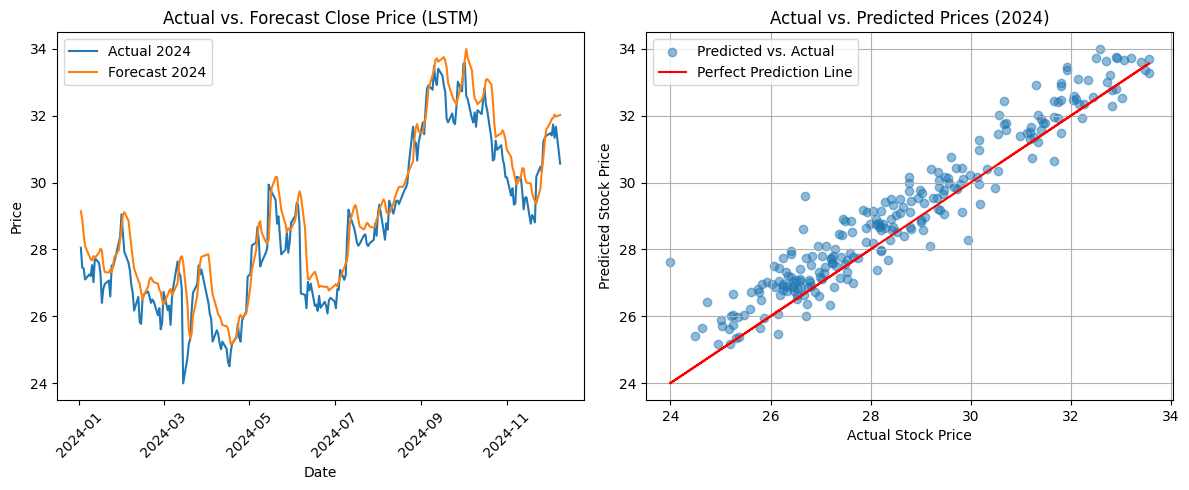

In [298]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# რეალური და პროგნოზირებული ფასები 
axes[0].plot(actual_2024.index, actual_2024, label="Actual 2024")
axes[0].plot(actual_2024.index, test_predict, label="Forecast 2024")
axes[0].set_title("Actual vs. Forecast Close Price (LSTM)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=45)

# პროგნოზი vs რეალური მნიშვნელობა
axes[1].scatter(actual_2024, test_predict, color="C0", alpha=0.5, label="Predicted vs. Actual")
axes[1].plot(actual_2024, actual_2024, color="red", label="Perfect Prediction Line")
axes[1].set_xlabel("Actual Stock Price")
axes[1].set_ylabel("Predicted Stock Price")
axes[1].set_title("Actual vs. Predicted Prices (2024)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()